# Notebook 01 – Thu thập, Khảo sát dữ liệu & Phân tích khám phá (EDA)

**Mục tiêu (bám sát Mục 3.1, 3.2 & 4.2 Báo cáo):**
1. **Phần A – Khảo sát chất lượng dữ liệu thô (Cell 1 → 3):** Đọc bộ dữ liệu *UCI Metro Interstate Traffic Volume* (`48.204` dòng × `9` cột) và bắt đúng **4 vấn đề dữ liệu** cần xử lý ở `note_02` (đứt quãng giờ đo, bẫy `NaN` & giờ `00:00` ở cột `holiday`, dòng trùng mốc giờ `date_time`, và 11 dòng lỗi cảm biến vật lý).
2. **Phần B – Phân tích khám phá 5 biểu đồ EDA (Cell 4 → 8):** Trực quan hóa quy luật phân bố, nhịp sinh hoạt Ngày thường vs Cuối tuần, Thời tiết & Ngày lễ, chu kỳ kép Thứ × Giờ và tính Tự tương quan (`Lag 1h – 48h`) để làm căn cứ chọn đặc trưng và mô hình.

### 1. Đọc dữ liệu gốc & Kiểm tra giai đoạn thời gian đo
* **Ý nghĩa:** Kiểm tra quy mô bảng dữ liệu và đối chiếu tổng số giờ lý thuyết trên đồng hồ với số mốc giờ thực tế có trong file để phát hiện các khoảng trống mất tín hiệu.

In [1]:
import os
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", font_scale=1.05)
RAW_PATH = os.path.join("..", "data", "raw", "metro_interstate_traffic_volume.csv")
FIGURES_DIR = os.path.join("..", "figures")
os.makedirs(FIGURES_DIR, exist_ok=True)

def luu_hinh(fig, ten_file):
    duong_dan = os.path.join(FIGURES_DIR, ten_file)
    fig.savefig(duong_dan, dpi=200, bbox_inches="tight")
    print("Đã lưu ảnh:", duong_dan)

# 1. Đọc file CSV và chuyển cột date_time từ chữ sang kiểu thời gian datetime64
df = pd.read_csv(RAW_PATH)
df["date_time"] = pd.to_datetime(df["date_time"])

# 2. So sánh tổng số giờ lý thuyết (nếu đo liên tục 24/24) với số giờ thực tế có
t_min, t_max = df["date_time"].min(), df["date_time"].max()
so_gio_ly_thuyet = int((t_max - t_min) / pd.Timedelta(hours=1)) + 1
so_gio_thuc_te = df["date_time"].nunique()

print(f"Quy mô dữ liệu gốc : {df.shape[0]:,} dòng × {df.shape[1]} cột")
print(f"Giai đoạn thu thập : {t_min} -> {t_max} (~{(t_max - t_min).days / 365.25:.2f} năm)")
print(f"Số giờ lý thuyết   : {so_gio_ly_thuyet:,} giờ | Thực tế có: {so_gio_thuc_te:,} giờ -> Khuyết: {so_gio_ly_thuyet - so_gio_thuc_te:,} giờ")
print("\nSố dòng ghi nhận theo từng năm (2014–2015 bị gián đoạn bảo trì nhiều):")
print(df["date_time"].dt.year.value_counts().sort_index().to_string())
display(df.head(5))

Quy mô dữ liệu gốc : 48,204 dòng × 9 cột
Giai đoạn thu thập : 2012-10-02 09:00:00 -> 2018-09-30 23:00:00 (~5.99 năm)
Số giờ lý thuyết   : 52,551 giờ | Thực tế có: 40,575 giờ -> Khuyết: 11,976 giờ

Số dòng ghi nhận theo từng năm (2014–2015 bị gián đoạn bảo trì nhiều):
date_time
2012     2559
2013     8573
2014     4839
2015     4373
2016     9306
2017    10605
2018     7949


,holiday,temp,rain_1h,snow_1h,clouds_all,weather_main,weather_description,date_time,traffic_volume
0,NaN,288.28,0.0,0.0,40,Clouds,scattered clouds,2012-10-02 09:00:00,5545
1,NaN,289.36,0.0,0.0,75,Clouds,broken clouds,2012-10-02 10:00:00,4516
2,NaN,289.58,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 11:00:00,4767
3,NaN,290.13,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 12:00:00,5026
4,NaN,291.14,0.0,0.0,75,Clouds,broken clouds,2012-10-02 13:00:00,4918


### 2. Kiểm tra giá trị khuyết (`holiday`) & Dòng trùng lặp mốc giờ (`date_time`)
* **Ý nghĩa:** Giải mã vì sao cột `holiday` báo khuyết `99,87%` (do chữ `'None'` bị đọc thành `NaN` và nhãn lễ chỉ gắn lúc `00:00:00`), đồng thời phân biệt dòng trùng hoàn toàn 9 cột với dòng trùng mốc giờ `date_time` do nhiều bản tin thời tiết xuất hiện trong cùng 1 giờ.

In [2]:
# 1. Bảng tổng hợp kiểu dữ liệu và tỷ lệ khuyết của 9 thuộc tính gốc
bang_khuyet = pd.DataFrame({
    "Kiểu dữ liệu": df.dtypes.astype(str),
    "Số ô trống (NaN)": df.isna().sum(),
    "Tỷ lệ trống (%)": (df.isna().mean() * 100).round(2),
    "Số giá trị khác nhau": df.nunique(),
})
display(bang_khuyet)

# 2. Kiểm tra đặc thù cột holiday: chỉ có 61 dòng có tên lễ và đều nằm ở đúng 0h sáng
gio_ghi_nhan_le = sorted(df.loc[df["holiday"].notna(), "date_time"].dt.hour.unique().tolist())
print(f"Số dòng có tên ngày lễ: {df['holiday'].notna().sum()} dòng | Giờ ghi nhận nhãn lễ trong ngày: {gio_ghi_nhan_le}")

# 3. Kiểm tra trùng lặp: trùng cả 9 cột vs trùng mốc thời gian date_time
so_trung_9_cot = int(df.duplicated().sum())
so_trung_gio = int(df.duplicated(subset=["date_time"]).sum())
print(f"Trùng hoàn toàn 9 cột: {so_trung_9_cot} dòng | Trùng mốc giờ date_time: {so_trung_gio:,} dòng")

gio_lap_nhieu = df["date_time"].value_counts().index[0]
print(f"\nVí dụ mốc giờ {gio_lap_nhieu} bị lặp nhiều dòng (cùng traffic_volume, chỉ khác nhãn thời tiết):")
display(df[df["date_time"] == gio_lap_nhieu])

Số dòng có tên ngày lễ: 61 dòng | Giờ ghi nhận nhãn lễ trong ngày: [0]
Trùng hoàn toàn 9 cột: 17 dòng | Trùng mốc giờ date_time: 7,629 dòng

Ví dụ mốc giờ 2013-04-18 22:00:00 bị lặp nhiều dòng (cùng traffic_volume, chỉ khác nhãn thời tiết):


,Kiểu dữ liệu,Số ô trống (NaN),Tỷ lệ trống (%),Số giá trị khác nhau
holiday,str,48143,99.87,11
temp,float64,0,0.00,5843
rain_1h,float64,0,0.00,372
snow_1h,float64,0,0.00,12
clouds_all,int64,0,0.00,60
weather_main,str,0,0.00,11
weather_description,str,0,0.00,38
date_time,datetime64[us],0,0.00,40575
traffic_volume,int64,0,0.00,6704


,holiday,temp,rain_1h,snow_1h,clouds_all,weather_main,weather_description,date_time,traffic_volume
5249,NaN,274.79,0.0,0.0,90,Mist,mist,2013-04-18 22:00:00,1532
5250,NaN,274.79,0.0,0.0,90,Drizzle,light intensity drizzle,2013-04-18 22:00:00,1532
5251,NaN,274.79,0.0,0.0,90,Rain,light rain,2013-04-18 22:00:00,1532
5252,NaN,274.79,0.0,0.0,90,Rain,moderate rain,2013-04-18 22:00:00,1532
5253,NaN,274.79,0.0,0.0,90,Snow,heavy snow,2013-04-18 22:00:00,1532
5254,NaN,274.79,0.0,0.0,90,Snow,snow,2013-04-18 22:00:00,1532


### 3. Thống kê mô tả các biến số & Phát hiện ngoại lai vật lý (Lỗi cảm biến)
* **Ý nghĩa:** Nhìn vào `min` và `max` để phát hiện các giá trị vô lý về mặt vật lý (`temp = 0 K = -273,15°C` và `rain_1h = 9.831,3 mm/giờ`), sau đó tạo bảng tạm `df_eda` (khử trùng giờ) để vẽ chuẩn xác 5 biểu đồ EDA.

In [3]:
# 1. Thống kê mô tả 5 biến định lượng gốc
display(df.describe(include=[np.number]).T.round(2))

print("Số dòng lỗi cảm biến nhiệt độ temp <= 0 Kelvin (-273.15°C):", int((df["temp"] <= 0).sum()))
print("Số dòng lỗi cảm biến lượng mưa rain_1h >= 500 mm/giờ     :", int((df["rain_1h"] >= 500).sum()))

# 2. Chuẩn bị bảng df_eda (mỗi giờ 1 dòng duy nhất, trích sẵn Thứ/Giờ/Ngày lễ) phục vụ vẽ 5 hình EDA
ngay_le_eda = set(df.loc[df["holiday"].notna(), "date_time"].dt.normalize())
df_eda = df.sort_values("date_time").drop_duplicates(subset=["date_time"], keep="first").copy()
df_eda["hour"] = df_eda["date_time"].dt.hour
df_eda["day_of_week"] = df_eda["date_time"].dt.dayofweek
df_eda["is_weekend"] = (df_eda["day_of_week"] >= 5).astype(int)
df_eda["is_holiday"] = df_eda["date_time"].dt.normalize().isin(ngay_le_eda).astype(int)

Số dòng lỗi cảm biến nhiệt độ temp <= 0 Kelvin (-273.15°C): 10
Số dòng lỗi cảm biến lượng mưa rain_1h >= 500 mm/giờ     : 1


,count,mean,std,min,25%,50%,75%,max
temp,48204.0,281.21,13.34,0.0,272.16,282.45,291.81,310.07
rain_1h,48204.0,0.33,44.79,0.0,0.00,0.00,0.00,9831.30
snow_1h,48204.0,0.00,0.01,0.0,0.00,0.00,0.00,0.51
clouds_all,48204.0,49.36,39.02,0.0,1.00,64.00,90.00,100.00
traffic_volume,48204.0,3259.82,1986.86,0.0,1193.00,3380.00,4933.00,7280.00


### 4. Hình EDA 1 – Phân bố của biến mục tiêu `traffic_volume`
* **Câu hỏi kiểm chứng:** Lưu lượng xe phân bố chuẩn một đỉnh hay hai đỉnh (ngày vs đêm)? Có điểm ngoại lai vượt râu Boxplot không?

Đã lưu ảnh: ..\figures\fig_eda1_distribution.png


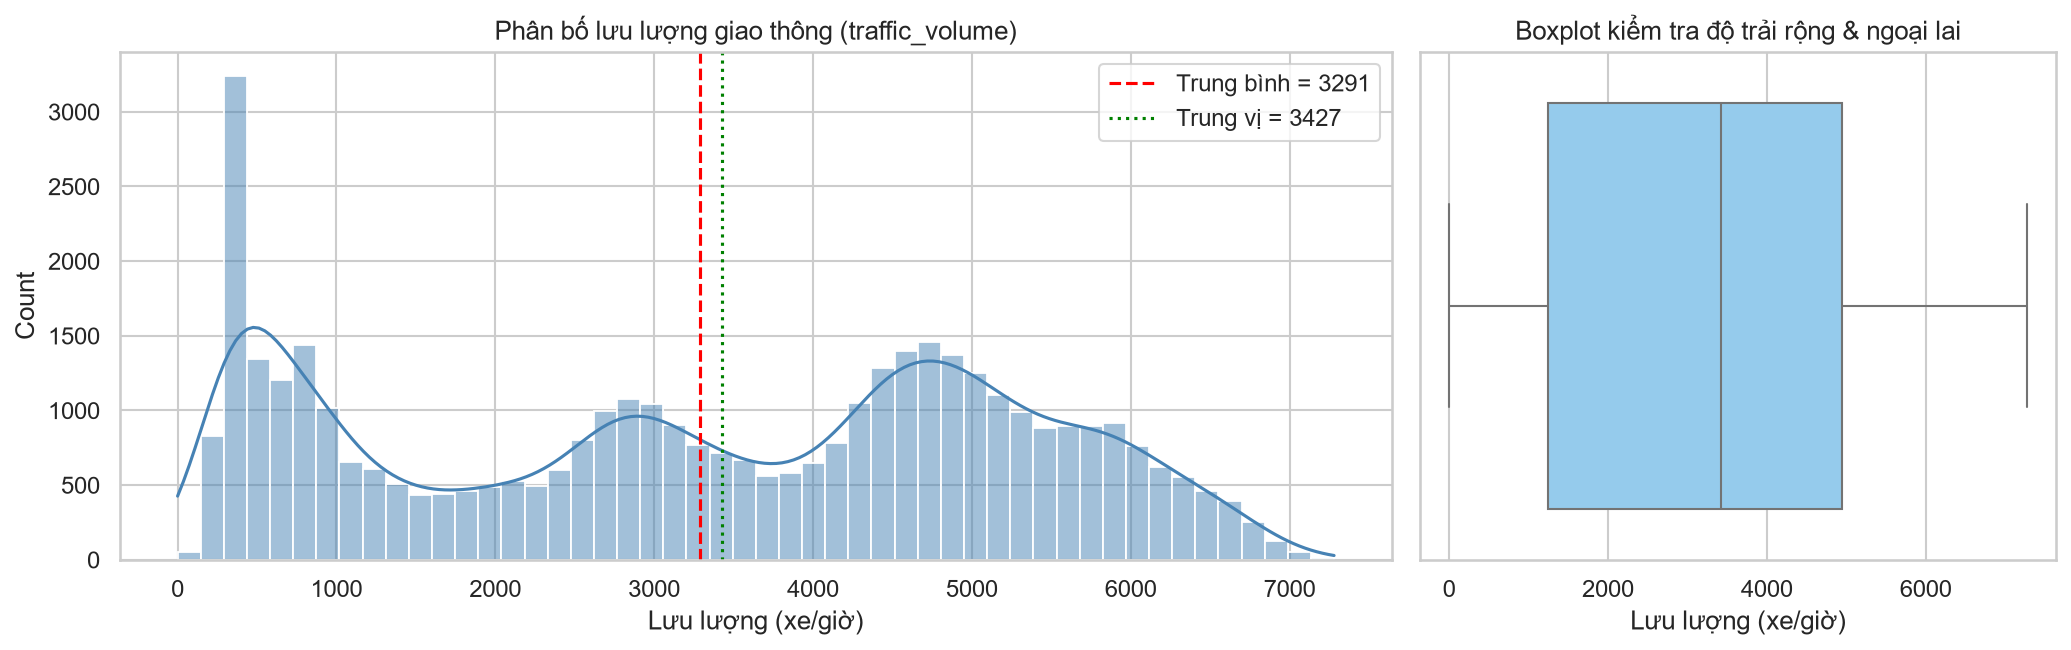

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), gridspec_kw={"width_ratios": [2, 1]})

sns.histplot(df_eda["traffic_volume"], bins=50, kde=True, color="steelblue", ax=axes[0])
axes[0].axvline(df_eda["traffic_volume"].mean(), color="red", linestyle="--", label=f"Trung bình = {df_eda['traffic_volume'].mean():.0f}")
axes[0].axvline(df_eda["traffic_volume"].median(), color="green", linestyle=":", label=f"Trung vị = {df_eda['traffic_volume'].median():.0f}")
axes[0].set_title("Phân bố lưu lượng giao thông (traffic_volume)")
axes[0].set_xlabel("Lưu lượng (xe/giờ)")
axes[0].legend()

sns.boxplot(x=df_eda["traffic_volume"], color="lightskyblue", ax=axes[1])
axes[1].set_title("Boxplot kiểm tra độ trải rộng & ngoại lai")
axes[1].set_xlabel("Lưu lượng (xe/giờ)")
plt.tight_layout()

luu_hinh(fig, "fig_eda1_distribution.png")
plt.show()

### 5. Hình EDA 2 – Lưu lượng trung bình theo giờ: Ngày thường vs Cuối tuần
* **Câu hỏi kiểm chứng:** Nhịp giao thông ngày đi làm (Thứ 2 – Thứ 6) khác ngày nghỉ cuối tuần (Thứ 7 – CN) như thế nào? Khung giờ cao điểm nằm ở đâu?

Đã lưu ảnh: ..\figures\fig_eda2_hourly_weekday_weekend.png


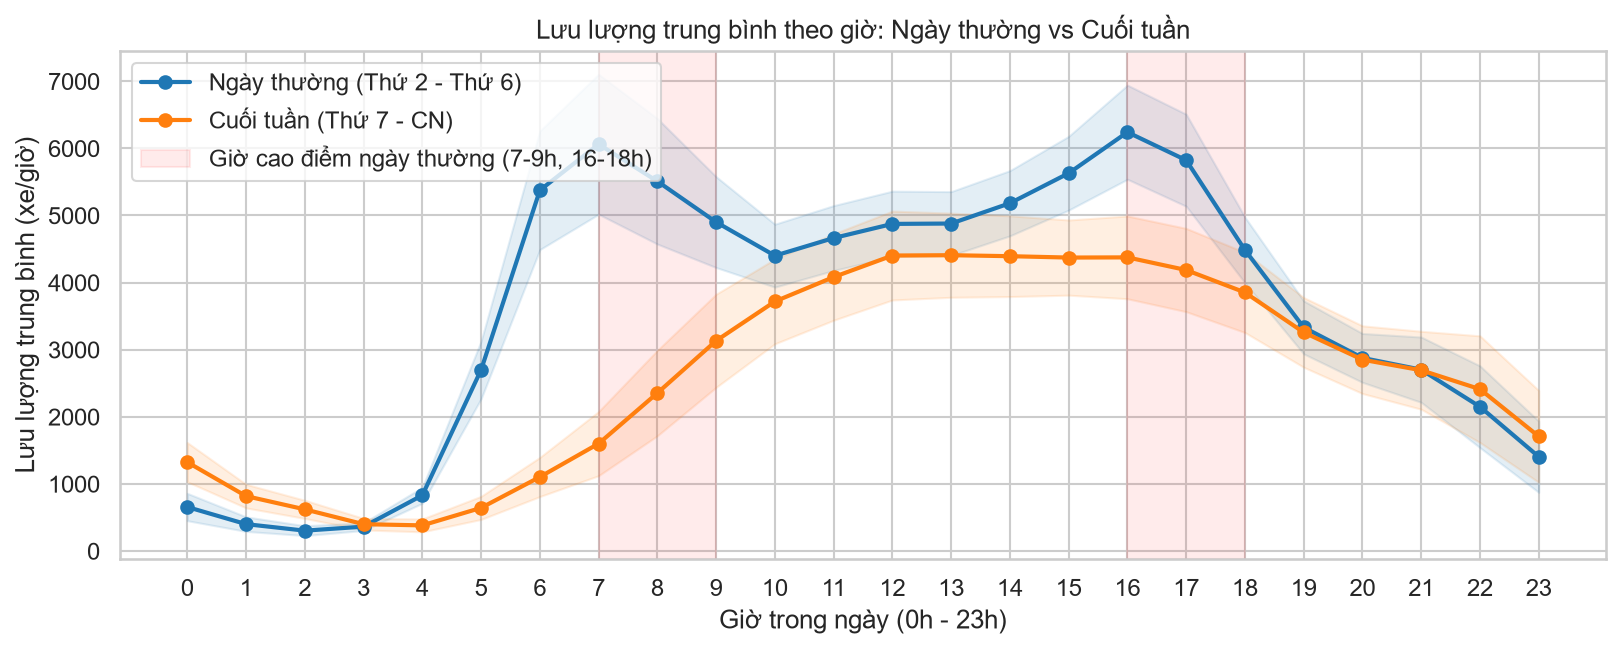

In [5]:
theo_gio = df_eda.groupby(["is_weekend", "hour"])["traffic_volume"].agg(["mean", "std"]).reset_index()

fig, ax = plt.subplots(figsize=(11, 4.5))
for wk, nhan, mau in [(0, "Ngày thường (Thứ 2 - Thứ 6)", "#1f77b4"), (1, "Cuối tuần (Thứ 7 - CN)", "#ff7f0e")]:
    d = theo_gio[theo_gio["is_weekend"] == wk]
    ax.plot(d["hour"], d["mean"], marker="o", label=nhan, color=mau, linewidth=2)
    ax.fill_between(d["hour"], d["mean"] - d["std"], d["mean"] + d["std"], alpha=0.12, color=mau)

ax.axvspan(7, 9, color="red", alpha=0.08, label="Giờ cao điểm ngày thường (7-9h, 16-18h)")
ax.axvspan(16, 18, color="red", alpha=0.08)
ax.set_xticks(range(0, 24))
ax.set_title("Lưu lượng trung bình theo giờ: Ngày thường vs Cuối tuần")
ax.set_xlabel("Giờ trong ngày (0h - 23h)")
ax.set_ylabel("Lưu lượng trung bình (xe/giờ)")
ax.legend()
plt.tight_layout()

luu_hinh(fig, "fig_eda2_hourly_weekday_weekend.png")
plt.show()

### 6. Hình EDA 3 – Ảnh hưởng của Thời tiết (`weather_main`) & Ngày lễ (`is_holiday`)
* **Câu hỏi kiểm chứng:** Các trạng thái thời tiết cực đoan và ngày nghỉ lễ làm giảm lưu lượng xe ra sao? (Cơ sở mã hóa One-Hot `weather_main` và lan truyền `is_holiday`).

Đã lưu ảnh: ..\figures\fig_eda3_weather_holiday.png


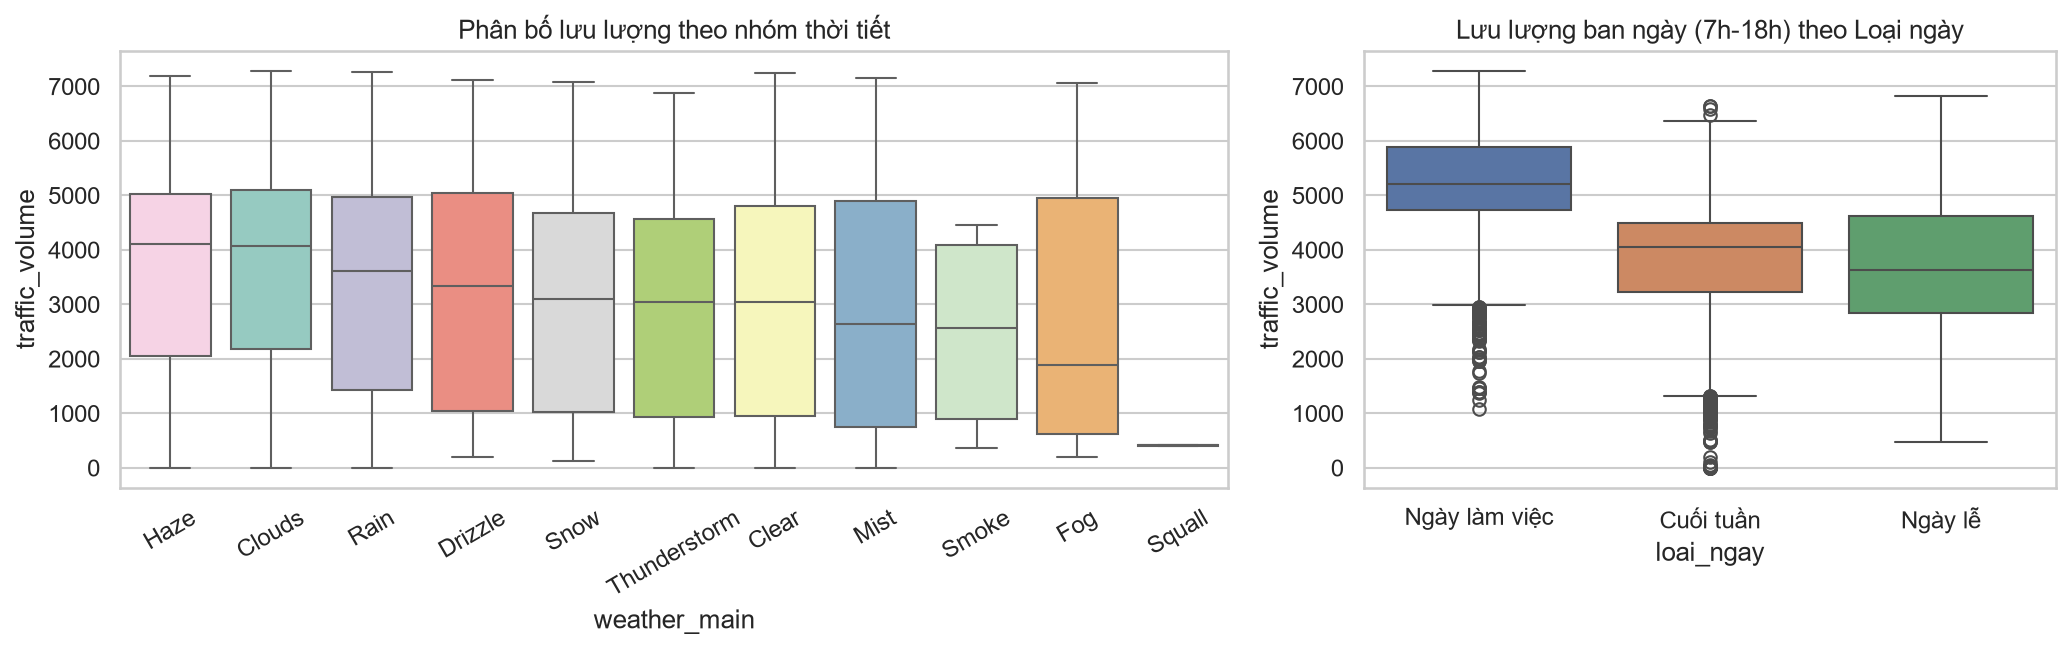

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), gridspec_kw={"width_ratios": [1.6, 1]})

thu_tu = df_eda.groupby("weather_main")["traffic_volume"].median().sort_values(ascending=False).index
sns.boxplot(data=df_eda, x="weather_main", y="traffic_volume", order=thu_tu, hue="weather_main", palette="Set3", legend=False, ax=axes[0])
axes[0].set_title("Phân bố lưu lượng theo nhóm thời tiết")
axes[0].tick_params(axis="x", rotation=30)

ban_ngay = df_eda[df_eda["hour"].between(7, 18)].copy()
ban_ngay["loai_ngay"] = np.select(
    [ban_ngay["is_holiday"] == 1, ban_ngay["is_weekend"] == 1],
    ["Ngày lễ", "Cuối tuần"],
    default="Ngày làm việc",
)
sns.boxplot(
    data=ban_ngay, x="loai_ngay", y="traffic_volume",
    order=["Ngày làm việc", "Cuối tuần", "Ngày lễ"],
    hue="loai_ngay", palette=["#4c72b0", "#dd8452", "#55a868"], legend=False, ax=axes[1]
)
axes[1].set_title("Lưu lượng ban ngày (7h-18h) theo Loại ngày")
plt.tight_layout()

luu_hinh(fig, "fig_eda3_weather_holiday.png")
plt.show()

### 7. Hình EDA 4 – Bản đồ nhiệt (Heatmap) chu kỳ kép Thứ trong tuần × Giờ trong ngày
* **Câu hỏi kiểm chứng:** Sự tương tác phi tuyến giữa `day_of_week` và `hour` thể hiện mạnh nhất ở những ô nào? (Lý giải vì sao mô hình Cây vượt trội hơn Hồi quy tuyến tính).

Đã lưu ảnh: ..\figures\fig_eda4_heatmap_day_hour.png


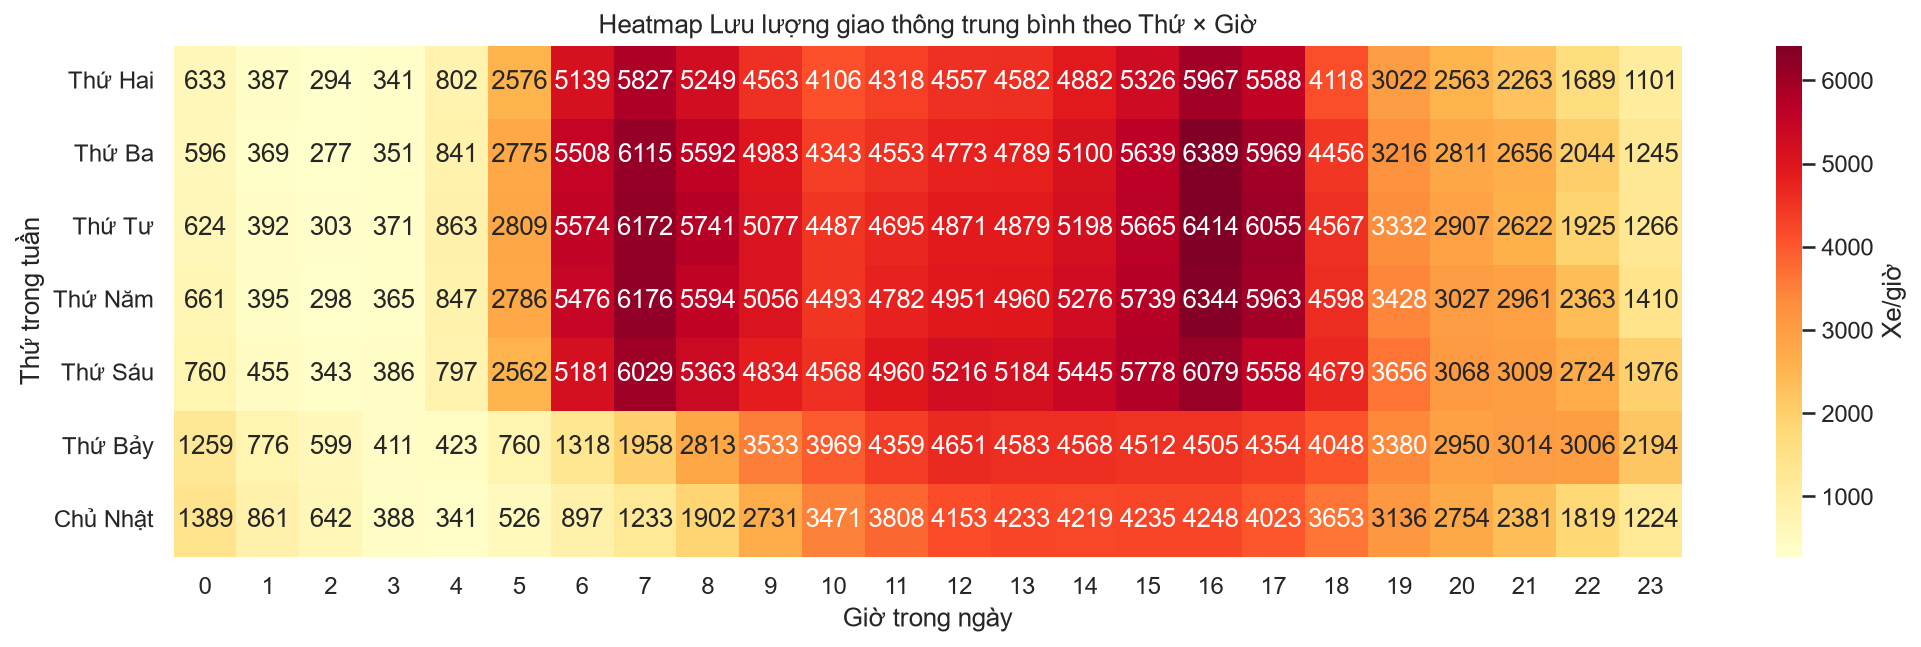

In [7]:
TEN_THU = ["Thứ Hai", "Thứ Ba", "Thứ Tư", "Thứ Năm", "Thứ Sáu", "Thứ Bảy", "Chủ Nhật"]
bang_nhiet = df_eda.pivot_table(index="day_of_week", columns="hour", values="traffic_volume", aggfunc="mean")
bang_nhiet.index = TEN_THU

fig, ax = plt.subplots(figsize=(14, 4.5))
sns.heatmap(bang_nhiet, cmap="YlOrRd", annot=True, fmt=".0f", cbar_kws={"label": "Xe/giờ"}, ax=ax)
ax.set_title("Heatmap Lưu lượng giao thông trung bình theo Thứ × Giờ")
ax.set_xlabel("Giờ trong ngày")
ax.set_ylabel("Thứ trong tuần")
plt.tight_layout()

luu_hinh(fig, "fig_eda4_heatmap_day_hour.png")
plt.show()

### 8. Hình EDA 5 – Ma trận tương quan Pearson & Tự tương quan theo độ trễ (`Lag 1h – 48h`)
* **Câu hỏi kiểm chứng:** Các biến thời tiết tương quan tuyến tính mạnh hay yếu? Chuỗi `traffic_volume` có quán tính tự tương quan mạnh nhất ở những độ trễ nào? (Cơ sở chọn `lag_1h`, `lag_24h`, `roll_3h` ở Bộ B).

Đã lưu ảnh: ..\figures\fig_eda5_correlation_autocorr.png
Tự tương quan nổi bật: lag_1h = 0.91 | lag_2h = 0.72 | lag_24h = 0.86 | lag_48h = 0.74


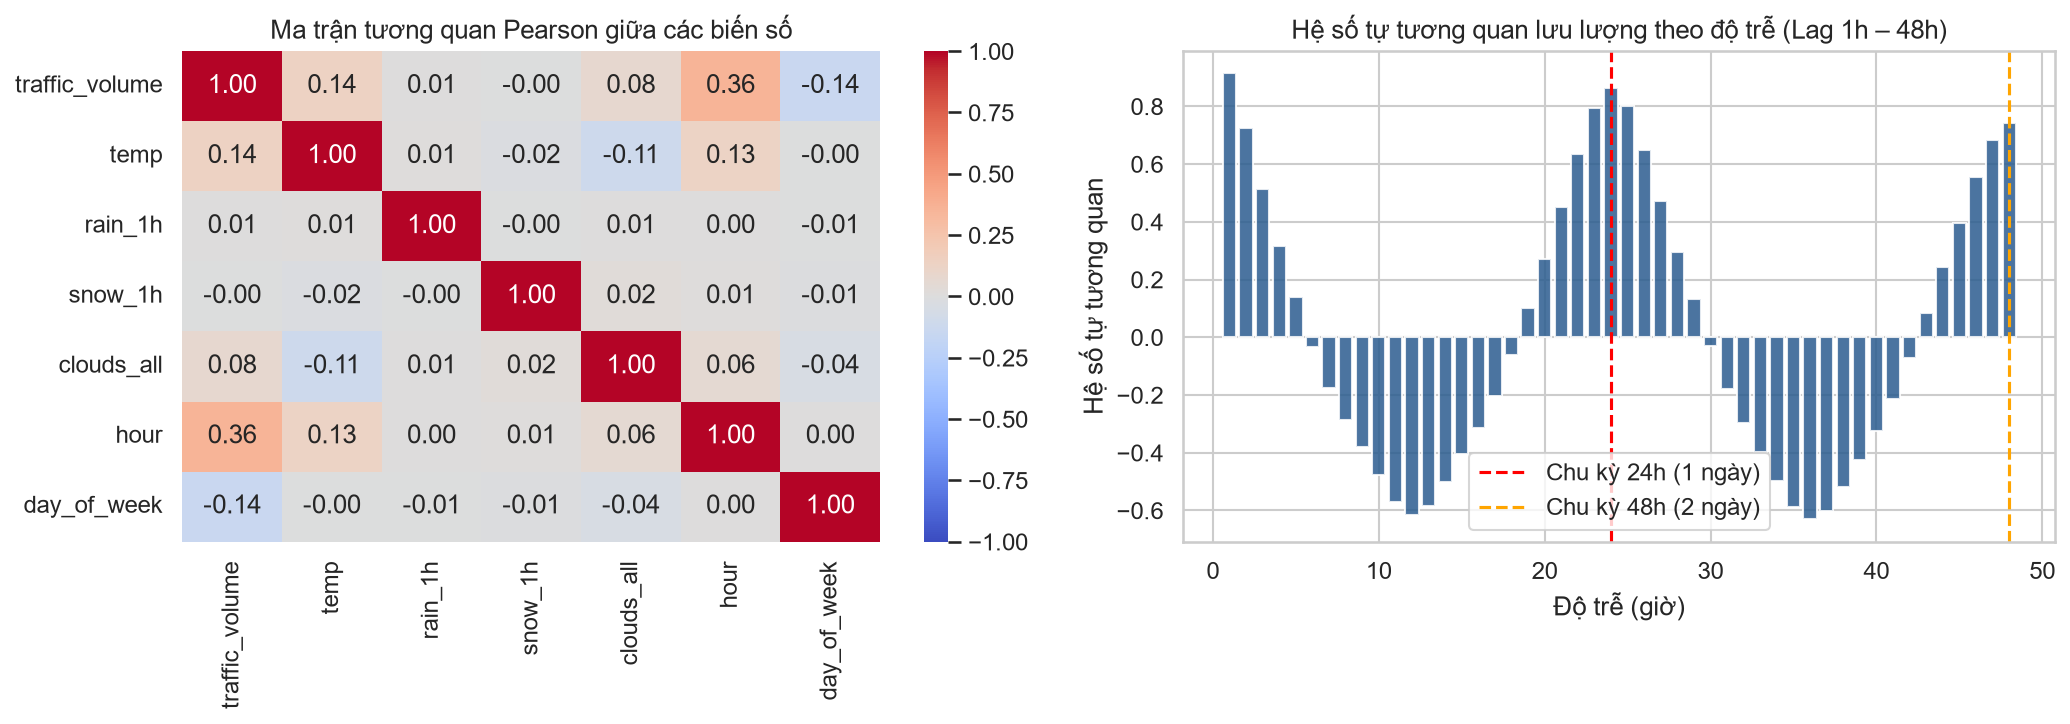

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# (a) Ma trận tương quan Pearson (tạm lọc bỏ 10 dòng lỗi temp = 0K để không làm lệch hệ số r)
num_cols = ["traffic_volume", "temp", "rain_1h", "snow_1h", "clouds_all", "hour", "day_of_week"]
df_corr = df_eda[df_eda["temp"] > 0][num_cols].corr()
sns.heatmap(df_corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1, ax=axes[0])
axes[0].set_title("Ma trận tương quan Pearson giữa các biến số")

# (b) Hệ số tự tương quan (Autocorrelation) trên lưới giờ chuẩn 1h (từ trễ 1h đến 48h)
chuoi_gio = df_eda.set_index("date_time")["traffic_volume"].asfreq("1h")
lags = range(1, 49)
autocorrs = [chuoi_gio.autocorr(lag=k) for k in lags]

axes[1].bar(lags, autocorrs, color="#2b5c8f", alpha=0.85)
axes[1].axvline(24, color="red", linestyle="--", label="Chu kỳ 24h (1 ngày)")
axes[1].axvline(48, color="orange", linestyle="--", label="Chu kỳ 48h (2 ngày)")
axes[1].set_title("Hệ số tự tương quan lưu lượng theo độ trễ (Lag 1h – 48h)")
axes[1].set_xlabel("Độ trễ (giờ)")
axes[1].set_ylabel("Hệ số tự tương quan")
axes[1].legend()
plt.tight_layout()

luu_hinh(fig, "fig_eda5_correlation_autocorr.png")
plt.show()
print(f"Tự tương quan nổi bật: lag_1h = {autocorrs[0]:.2f} | lag_2h = {autocorrs[1]:.2f} | lag_24h = {autocorrs[23]:.2f} | lag_48h = {autocorrs[47]:.2f}")

### Tổng kết kết quả Khảo sát & Phân tích khám phá (EDA)

1. **Chất lượng & cấu trúc chuỗi thời gian (Cơ sở tiền xử lý ở `note_02`):**
   - Dữ liệu gốc gồm **48.204 bản ghi** trải dài gần 6 năm (10/2012 – 09/2018), nhưng chỉ có **40.575 mốc giờ duy nhất** (khuyết 11.976 giờ gián đoạn và lặp 7.629 dòng do cùng một giờ có nhiều bản tin thời tiết khác nhau).
   - Phát hiện ngoại lai vật lý rõ rệt: **10 bản ghi** lỗi cảm biến nhiệt độ `temp = 0 K` (`-273.15°C`) và **1 bản ghi** mưa phi thực tế `rain_1h = 9831.3 mm/giờ`.
   - Cột `holiday` chỉ được gắn nhãn tại đúng mốc `00:00:00` (61 bản ghi), cần lan truyền nhãn cho toàn bộ 24 giờ trong ngày lễ ở bước xử lý tiếp theo.

2. **Các quy luật chính rút ra từ EDA:**
   - **Phân bố hai đỉnh (Bimodal):** `traffic_volume` tập trung ở hai vùng rõ rệt — cụm thấp điểm ban đêm (~500–1.000 xe/giờ) và cụm cao điểm ban ngày (~4.500–5.500 xe/giờ).
   - **Tính chu kỳ theo giờ & thứ trong tuần:** Ngày thường (Thứ Hai – Thứ Sáu) có 2 đỉnh cao điểm sắc nét lúc **7h–8h** (đi làm) và **16h–17h** (tan tầm, đạt trung bình > 5.700–6.400 xe/giờ). Cuối tuần (Thứ Bảy – Chủ Nhật) chỉ có 1 đỉnh thoải kéo dài từ **12h đến 16h**.
   - **Tác động thời tiết & tính tự tương quan:** Thời tiết khắc nghiệt (`Squall`, `Snow`, `Fog`) làm giảm lưu lượng đáng kể. Biến mục tiêu có tính tự tương quan rất mạnh tại các độ trễ ngắn (`lag 1h`, `lag 2h`) và lặp lại chu kỳ rõ rệt tại **`lag 24h`** và **`lag 48h`**, khẳng định hiệu quả của việc trích xuất các đặc trưng trễ (lag features), cửa sổ trượt (rolling) và mã hóa tuần hoàn `sin/cos` theo giờ/thứ ở bước tiếp theo.